# City x City RF transferability — plots

Loads the pickle produced by `run_rf_city_city.py` and plots:
- **OA**: one heatmap, rows = train city, columns = test city
- **PA** and **UA**: one small heatmap per class, rows = train city, columns = test city (color only, exact numbers not important)

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PICKLE_PATH = Path("./tables/city_city_results.pkl")

with open(PICKLE_PATH, "rb") as f:
    data = pickle.load(f)

results = data["results"]
class_labels = data["class_labels"]
city_names = data["city_names"]

print("Train cities:", city_names)
print("Classes:", class_labels)


Train cities: ['basel', 'bern', 'geneva', 'lausanne', 'lugano', 'zurich']
Classes: {1: 'Compact MR', 2: 'Open MR', 3: 'Open LR', 4: 'Large LR', 5: 'Dense Trees', 6: 'Low plants', 7: 'Bare/Paved', 8: 'Water'}


## Overall Accuracy (OA) heatmap

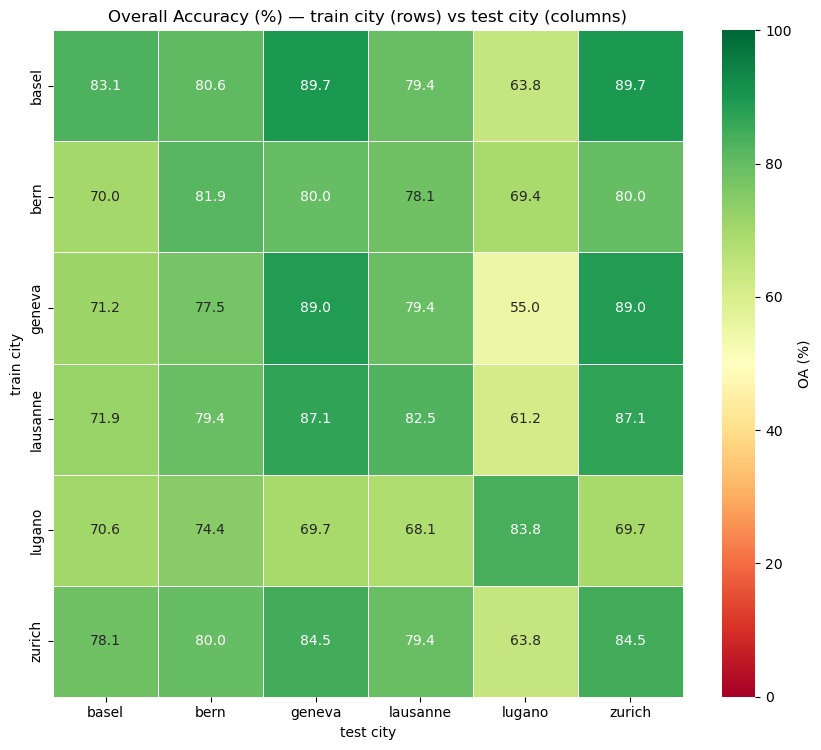

In [2]:
# Build OA matrix: rows = train city, columns = test city
oa_matrix = pd.DataFrame(
    {test_city: [results[train_city][test_city]["OA"] for train_city in city_names]
     for test_city in city_names},
    index=city_names,
)
oa_matrix = oa_matrix[city_names]  # keep consistent column order
oa_matrix.index.name = "train city"
oa_matrix.columns.name = "test city"

fig, ax = plt.subplots(figsize=(1.1 * len(city_names) + 2, 1.1 * len(city_names) + 1))
sns.heatmap(
    oa_matrix,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "OA (%)"},
    linewidths=0.5,
    linecolor="white",
    ax=ax,
)
ax.set_title("Overall Accuracy (%) — train city (rows) vs test city (columns)")
plt.tight_layout()
plt.savefig("./images/OA_heatmap_city_city.png", dpi=200, bbox_inches="tight")
plt.show()


## Per-class Producer's Accuracy (PA) and User's Accuracy (UA)

One small heatmap per class. Rows = train city, columns = test city. Color encodes accuracy (0-100%); exact numbers are secondary here, so no annotations by default (set `ANNOTATE = True` below if you want them).

In [3]:
ANNOTATE = False  # set True to print numbers on each small heatmap

def build_per_class_matrices(metric_key):
    """Return dict: class_id -> DataFrame (train city rows x test city cols)."""
    class_ids = sorted(class_labels.keys())
    matrices = {}
    for i, cid in enumerate(class_ids):
        mat = pd.DataFrame(
            {test_city: [results[train_city][test_city][metric_key][i] for train_city in city_names]
             for test_city in city_names},
            index=city_names,
        )
        mat = mat[city_names]
        matrices[cid] = mat
    return matrices


def plot_small_multiples(metric_key, title):
    matrices = build_per_class_matrices(metric_key)
    class_ids = sorted(class_labels.keys())
    n = len(class_ids)
    ncols = 4
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 2.8 * nrows))
    axes = np.array(axes).reshape(-1)

    for i, cid in enumerate(class_ids):
        ax = axes[i]
        mat = matrices[cid]
        sns.heatmap(
            mat,
            cmap="RdYlGn",
            vmin=0,
            vmax=100,
            cbar=False,
            annot=ANNOTATE,
            fmt=".0f",
            annot_kws={"fontsize": 6},
            linewidths=0.3,
            linecolor="white",
            ax=ax,
            square=True,
        )
        ax.set_title(class_labels[cid], fontsize=10)
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="both", labelsize=6)
        if i % ncols != 0:
            ax.set_yticklabels([])
        if i < (nrows - 1) * ncols:
            ax.set_xticklabels([])

    for j in range(n, len(axes)):
        axes[j].axis("off")

    # Shared colorbar
    sm = plt.cm.ScalarMappable(cmap="RdYlGn", norm=plt.Normalize(vmin=0, vmax=100))
    sm.set_array([])
    fig.colorbar(sm, ax=axes.tolist(), shrink=0.6, label=f"{metric_key} (%)", pad=0.01)

    fig.suptitle(f"{title} — rows: train city, columns: test city", y=1.02)
    return fig


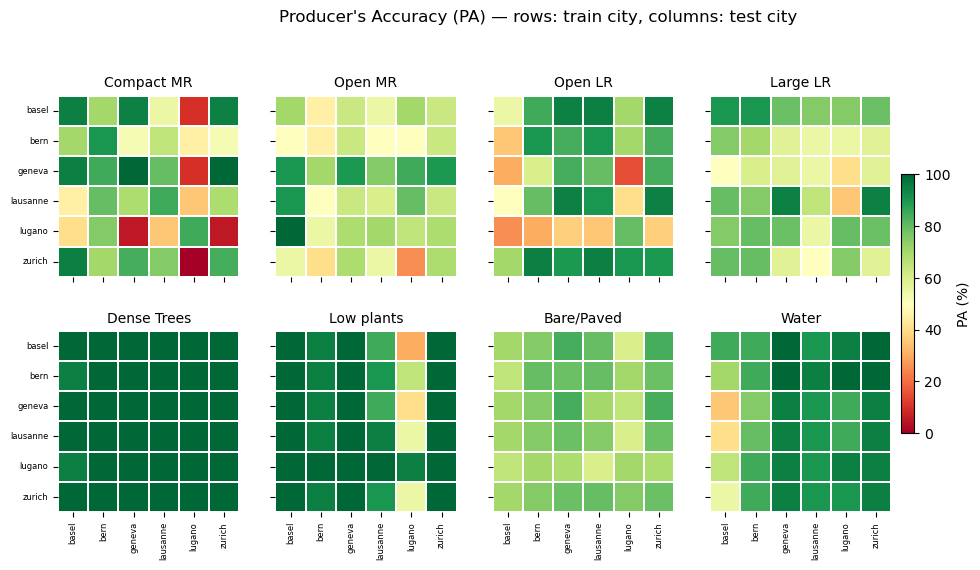

In [4]:
fig_pa = plot_small_multiples("PA", "Producer's Accuracy (PA)")
plt.savefig("./images/PA_heatmap_grid_city_city.png", dpi=200, bbox_inches="tight")
plt.show()


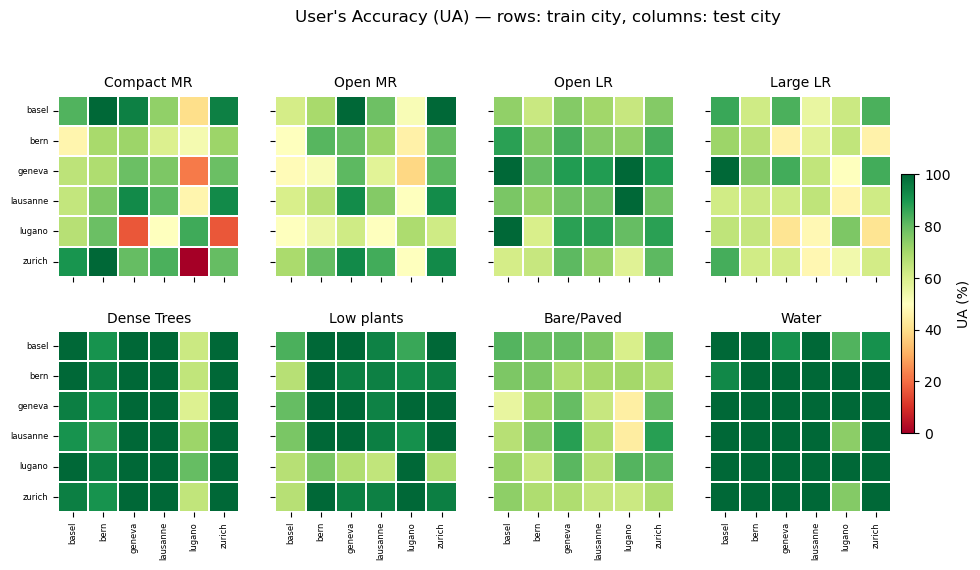

In [5]:
fig_ua = plot_small_multiples("UA", "User's Accuracy (UA)")
plt.savefig("./images/UA_heatmap_grid_city_city.png", dpi=200, bbox_inches="tight")
plt.show()
